In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns

In [2]:
results_path = "/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/BinaryClassifier/longer_run/"
results_filename = results_path+"results.csv"
results = pd.read_csv(results_filename)
results.head()

,Unnamed: 0,hnl_likelihood,energy,position_x,position_y,position_z,azimuth,zenith,is_hnl,pid,interaction_type,elasticity,dbang_decay_length,event_weight,event_no
0,0,1.000000e+00,180.718314,-285.779920,93.226979,-581.358286,2.187603,2.511337,1.0,-16.0,-1.0,-1.0,274.109386,8.643268e-13,2501.0
1,1,9.999990e-01,11.752695,58.598784,18.154397,-284.550596,0.639281,2.160721,1.0,16.0,-1.0,-1.0,516.881624,7.059185e-10,7823.0
2,2,2.135861e-10,75.850658,47.645398,100.642646,-470.273246,1.649169,2.029573,1.0,-16.0,-1.0,-1.0,5.647901,3.718369e-14,2147.0
3,3,1.000000e+00,77.558834,76.357469,17.309466,-531.167868,0.816802,2.034906,1.0,16.0,-1.0,-1.0,83.241630,8.721821e-12,3377.0
4,4,9.994504e-01,25.052848,2.270031,-119.508723,-410.579685,3.591331,1.822711,1.0,16.0,-1.0,-1.0,87.335421,1.462962e-11,16836.0


In [3]:
probable = results['event_weight']!= -np.inf
hnl = results['is_hnl']==1.0
hnl_mask = hnl & probable
background_mask = results['is_hnl']==0.0

tau_plus = results['pid']==16.0
tau_minus = results['pid']==-16.0
mu_plus = results['pid']==14.0
mu_minus = results['pid']==-14.0
e_plus = results['pid']==12.0
e_minus = results['pid']==-12.0

nutau_mask = (tau_plus | tau_minus) & probable
numu_mask = mu_plus | mu_minus
nue_mask = e_plus | e_minus

Text(0.5, 1.0, 'Initial classifier attempt')

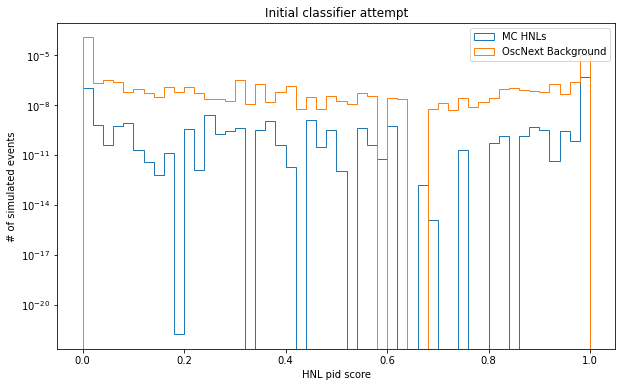

In [4]:
plt.figure(figsize=(10, 6))
# bins = np.logspace(-0.5, 4, 500)

plt.hist(results['hnl_likelihood'][hnl_mask], bins = 50, weights=results['event_weight'][hnl_mask], histtype="step", label="MC HNLs")
plt.hist(results['hnl_likelihood'][background_mask], bins = 50, histtype="step",weights=results[background_mask]['event_weight'], label="OscNext Background")

# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('# of simulated events')
plt.title("Initial classifier attempt")

Text(0, 0.5, 'Proportion of events')

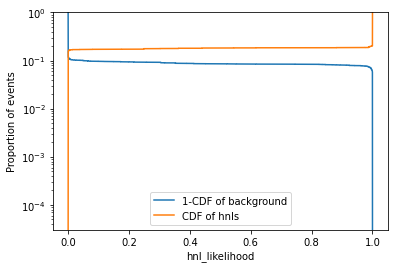

In [5]:
#Make CDF of the above plot. What's the fraction of neutrino background above a given pid score?#
#What's the fraction of hnls below a given pid score?
#MAke weighted version of the above - we need to know the impact of the flux to do science!!!!

ax = sns.ecdfplot(
    data=results[background_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='event_weight',
    label="1-CDF of background")

ax1 = sns.ecdfplot(
    data=results[hnl_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=False, 
    log_scale=[False, True],
    weights='event_weight',
    label="CDF of hnls")

ax.legend()
ax.set_ylabel("Proportion of events")

Text(0, 0.5, 'Proportion of events above likelihood')

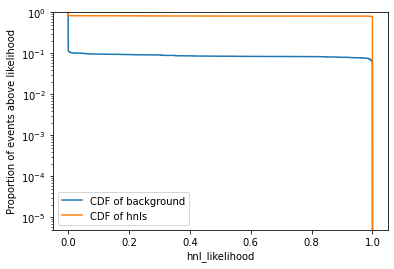

In [6]:
ax = sns.ecdfplot(
    data=results[background_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='event_weight', 
    label="CDF of background")
ax1 = sns.ecdfplot(
    data=results[hnl_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='event_weight',
    label="CDF of hnls")
ax.legend()
ax.set_ylabel("Proportion of events above likelihood")

Text(0.5, 1.0, 'Initial classifier attempt')

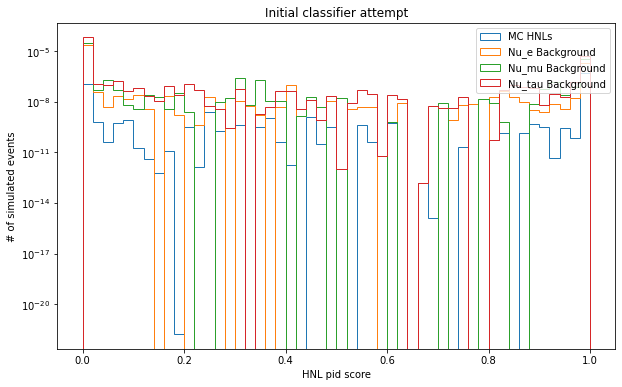

In [7]:
plt.figure(figsize=(10, 6))
# bins = np.logspace(-0.5, 4, 500)

plt.hist(results['hnl_likelihood'][hnl_mask], bins = 50, histtype="step", weights=results['event_weight'][hnl_mask], label="MC HNLs")
plt.hist(results['hnl_likelihood'][nue_mask], bins = 50, histtype="step", weights=results['event_weight'][nue_mask],label="Nu_e Background")
plt.hist(results['hnl_likelihood'][numu_mask], bins = 50, histtype="step", weights=results['event_weight'][numu_mask],label="Nu_mu Background")
plt.hist(results['hnl_likelihood'][nutau_mask], bins = 50, histtype="step", weights=results['event_weight'][nutau_mask],label="Nu_tau Background")

# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('# of simulated events')
plt.title("Initial classifier attempt")

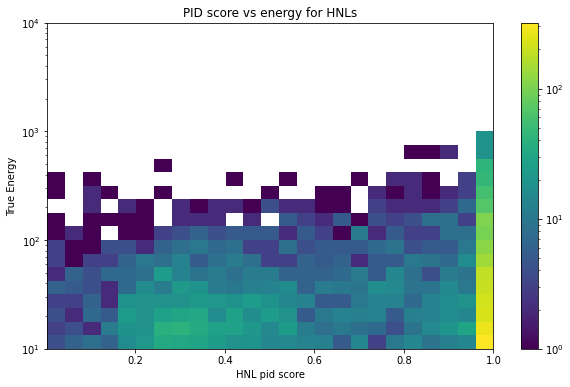

In [5]:
plt.figure(figsize=(10, 6))
xbins = 25
ybins = np.logspace(1, 4, xbins)
plt.hist2d(results['hnl_likelihood'][hnl_mask], results['energy'][hnl_mask], bins=[xbins, ybins], norm=colors.LogNorm())

# plt.xscale('log')
plt.yscale('log')
# plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('True Energy')
plt.title("PID score vs energy for HNLs")
plt.colorbar()

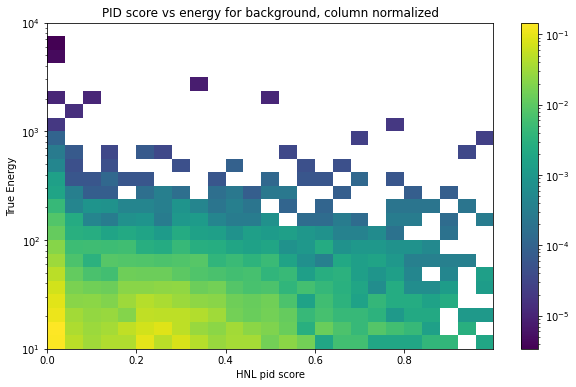

In [45]:
plt.figure(figsize=(10, 6))
xbins = 25
ybins = np.logspace(1, 4, xbins)
plt.hist2d(results['hnl_likelihood'][background_mask], results['energy'][background_mask], bins=[xbins, ybins], norm=colors.LogNorm(), density=True)

# plt.xscale('log')
plt.yscale('log')
# plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('True Energy')
plt.title("PID score vs energy for background, column normalized")
plt.colorbar()

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/site-packages/ipykernel_launcher.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  after removing the cwd from sys.path.


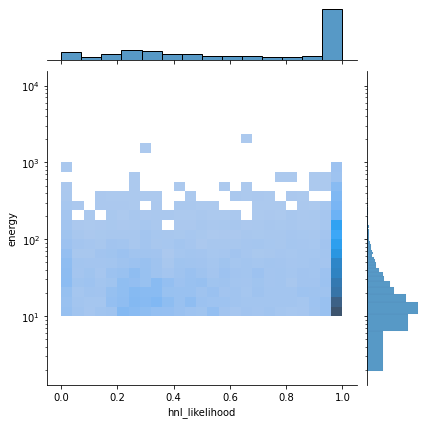

In [46]:
#maybe also use kind=kde?


g = sns.jointplot(data=results[hnl_mask], x="hnl_likelihood", y="energy", kind="hist", bins = [xbins, ybins])

# Set the axes to log scale
# g.ax_joint.set_xscale('log')
g.ax_joint.set_yscale('log')

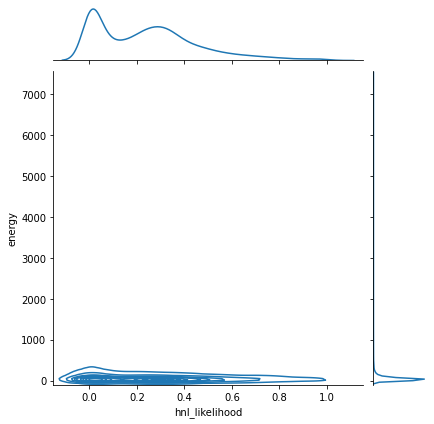

In [40]:
#maybe also use kind=kde?


g = sns.jointplot(data=results[background_mask], x="hnl_likelihood", y="energy", kind="kde")

# Set the axes to log scale
# g.ax_joint.set_xscale('log')
# g.ax_joint.set_yscale('log')